# Data Cleaning

In [1]:
# Imports
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)

In [2]:
from pathlib import Path
import pandas as pd

# Resolve path relative to this script
cwd = Path.cwd()
print(cwd)

# If you're inside "notebooks", go up one level
# if cwd.name == "notebooks":
#     base_dir = cwd.parent
# else:
#     base_dir = cwd

# data_file_path = base_dir/ "heart_disease_uci.csv"
# print(data_file_path)

/Users/rodchen/SJSU/Fall_25/CMPE_255/cmpe255-heart_disease_analysis/notebooks


In [3]:
# Import data from the Google Sheet into a pandas dataframe

import pandas as pd

sheet_id = "1B47TGfCqgvAy-A4WsLmUI7zWnTWbusYX9f0Eqgfchx8"
sheet_name = "heart_disease_uci"

url_part1 = f"https://docs.google.com/spreadsheets/d/{sheet_id}/"
url_part2 = f"gviz/tq?tqx=out:csv&sheet={sheet_name}"
url = url_part1 + url_part2

df = pd.read_csv(url)
print(df.head())

   id  age     sex    dataset               cp  trestbps   chol    fbs  \
0   1   63    Male  Cleveland   typical angina     145.0  233.0   True   
1   2   67    Male  Cleveland     asymptomatic     160.0  286.0  False   
2   3   67    Male  Cleveland     asymptomatic     120.0  229.0  False   
3   4   37    Male  Cleveland      non-anginal     130.0  250.0  False   
4   5   41  Female  Cleveland  atypical angina     130.0  204.0  False   

          restecg  thalch  exang  oldpeak        slope   ca  \
0  lv hypertrophy   150.0  False      2.3  downsloping  0.0   
1  lv hypertrophy   108.0   True      1.5         flat  3.0   
2  lv hypertrophy   129.0   True      2.6         flat  2.0   
3          normal   187.0  False      3.5  downsloping  0.0   
4  lv hypertrophy   172.0  False      1.4    upsloping  0.0   

                thal  num  
0       fixed defect    0  
1             normal    2  
2  reversable defect    1  
3             normal    0  
4             normal    0  


# Data Exploration

In [4]:
# (rows, columns)
df.shape

(920, 16)

In [5]:
# Columns names
print(df.columns.tolist())

['id', 'age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']


In [6]:
# Data Overview
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB


In [7]:
# Preview first 5 rows
df.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [8]:
# Quick descriptive statistics for numeric values (int, float)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,920.0,460.500000,265.725422,1.0,230.75,460.5,690.25,920.0
age,920.0,53.510870,9.424685,28.0,47.00,54.0,60.00,77.0
trestbps,861.0,132.132404,19.066070,0.0,120.00,130.0,140.00,200.0
chol,890.0,199.130337,110.780810,0.0,175.00,223.0,268.00,603.0
thalch,865.0,137.545665,25.926276,60.0,120.00,140.0,157.00,202.0
oldpeak,858.0,0.878788,1.091226,-2.6,0.00,0.5,1.50,6.2
ca,309.0,0.676375,0.935653,0.0,0.00,0.0,1.00,3.0
num,920.0,0.995652,1.142693,0.0,0.00,1.0,2.00,4.0


In [9]:
# Quick Descriptive Statistics for Categorical Values (object type)
df.describe(include=['object']).T

,count,unique,top,freq
sex,920,2,Male,726
dataset,920,4,Cleveland,304
cp,920,4,asymptomatic,496
fbs,830,2,False,692
restecg,918,3,normal,551
exang,865,2,False,528
slope,611,3,flat,345
thal,434,3,normal,196


In [10]:
# Show unique values for each column (categorical columns)
for col in df.select_dtypes(include=['object']).columns:
	print(f"'{col}': {df[col].unique()}")


'sex': ['Male' 'Female']
'dataset': ['Cleveland' 'Hungary' 'Switzerland' 'VA Long Beach']
'cp': ['typical angina' 'asymptomatic' 'non-anginal' 'atypical angina']
'fbs': [True False nan]
'restecg': ['lv hypertrophy' 'normal' 'st-t abnormality' nan]
'exang': [False True nan]
'slope': ['downsloping' 'flat' 'upsloping' nan]
'thal': ['fixed defect' 'normal' 'reversable defect' nan]


In [11]:
# Table showing the columns, the null counts, and the percentage of nulls
null_data = pd.DataFrame({
	'column': df.columns,
	'null_count': df.isnull().sum(),
	'null_%': (df.isnull().mean() * 100).round(2)
}).reset_index(drop=True)

null_data

,column,null_count,null_%
0,id,0,0.00
1,age,0,0.00
2,sex,0,0.00
3,dataset,0,0.00
4,cp,0,0.00
5,trestbps,59,6.41
6,chol,30,3.26
7,fbs,90,9.78
8,restecg,2,0.22
9,thalch,55,5.98


In [12]:
# Top 5 columns with the most nulls
null_data.sort_values(by='null_count', ascending=False).head(5)

,column,null_count,null_%
13,ca,611,66.41
14,thal,486,52.83
12,slope,309,33.59
7,fbs,90,9.78
11,oldpeak,62,6.74


In [13]:
df.duplicated().sum()

np.int64(0)

# Data Preprocessing

In [14]:
# Drop irrevlevant columns
if 'id' in df.columns:
	df = df.drop(columns=['id'])
	print('Column "id" was dropped.')
else:
	print('Column "id" not found, not doing anything.')

Column "id" was dropped.


In [15]:
# Convert target variable (num) to binary (0 = no heart disease, >=1 = heart disease), then drop orignal 'num' column
if 'num' in df.columns:
    df['target'] = (df['num'] > 0).astype(int)
    df.drop(columns=['num'], inplace=True)
else:
    print('Column "num" not found, not doing anything.')

In [16]:
# Handling columns with missing values > 30% to avoid too much imputation
cols_to_drop = ['ca', 'thal', 'slope']
if any(col in df.columns for col in cols_to_drop):
    df.drop(columns=cols_to_drop, inplace=True, errors="ignore")
    print(f"Dropped columns: {', '.join(cols_to_drop)}")
else:
	print("No columns dropped.")

Dropped columns: ca, thal, slope


In [17]:
# Fixing invalid values and impute with median
cols_with_invalid = ['trestbps', 'chol']

for col in cols_with_invalid:
    if col in df.columns:
        # replace 0 with NaN
        df[col] = df[col].replace(0, np.nan)

        # compute median (ignoring NaNs)
        median_val = df[col].median()

        # impute NaN with median
        df[col] = df[col].fillna(median_val)

        print(f"Replaced 0 and NaN in'{col}' with median = {median_val}")
    else:
        print(f"Column '{col}' not found, not doing anything.")

Replaced 0 and NaN in'trestbps' with median = 130.0
Replaced 0 and NaN in'chol' with median = 239.5


In [18]:
# replace NaN with median for the remaining numeric columns
remaining_numeric_cols = ['thalch', 'oldpeak']

for col in remaining_numeric_cols:
    if col in df.columns:
        # Compute median ignoring NaN
        median_val = df[col].median()

        # Fill NaN with median
        df[col] = df[col].fillna(median_val)

        print(f"Imputed NaN in '{col}' with median = {median_val}")
    else:
        print(f"Column '{col}' not found, not doing anything.")


Imputed NaN in 'thalch' with median = 140.0
Imputed NaN in 'oldpeak' with median = 0.5


In [19]:
# Impute missing values for categorical columns with mode
categorical_cols = df.select_dtypes(include=['object']).columns

for col in categorical_cols:
    df[col] = df[col].astype('category')
    if df[col].isnull().sum() > 0:
        mode_val = df[col].mode()[0]
        df[col] = df[col].fillna(mode_val)
        print(f"Imputed NaN in '{col}' with mode = {mode_val}")

Imputed NaN in 'fbs' with mode = False
Imputed NaN in 'restecg' with mode = normal
Imputed NaN in 'exang' with mode = False


# Inspection After Preprocessing

In [20]:
print('shape (rows, columns):', df.shape)

# Check for any remaining missing values
missing_report = df.isna().sum()
print("\nMissing values per column:")
print(missing_report[missing_report > 0] if missing_report.sum() > 0 else "No missing values")

# Data types
print("\n\nData types:")
print(df.dtypes)

# Numeric summary
print("\nSummary stats (numeric):")
display(df.describe().T)

shape (rows, columns): (920, 12)

Missing values per column:
No missing values


Data types:
age            int64
sex         category
dataset     category
cp          category
trestbps     float64
chol         float64
fbs         category
restecg     category
thalch       float64
exang       category
oldpeak      float64
target         int64
dtype: object

Summary stats (numeric):


,count,mean,std,min,25%,50%,75%,max
age,920.0,53.510870,9.424685,28.0,47.00,54.0,60.0,77.0
trestbps,920.0,132.136957,17.929761,80.0,120.00,130.0,140.0,200.0
chol,920.0,245.222826,51.785328,85.0,217.75,239.5,267.0,603.0
thalch,920.0,137.692391,25.145235,60.0,120.00,140.0,156.0,202.0
oldpeak,920.0,0.853261,1.058049,-2.6,0.00,0.5,1.5,6.2
target,920.0,0.553261,0.497426,0.0,0.00,1.0,1.0,1.0


In [21]:
# Ensure the processed directory exists
if cwd.name == "notebooks":
    base_dir = cwd.parent
else:
    base_dir = cwd
processed_dir = base_dir
processed_dir.mkdir(parents=True, exist_ok=True)

# Save as CSV
output_path = processed_dir / "heart_disease_clean.csv"
df.to_csv(output_path, index=False)

print(f"Cleaned dataset saved at: {output_path}")

Cleaned dataset saved at: /Users/rodchen/SJSU/Fall_25/CMPE_255/cmpe255-heart_disease_analysis/heart_disease_clean.csv


### Summary of this Jupyter Notebook
This jupyter notbook includes mainly the **data exploration** where we take an initial check on the raw data to understand its data structure and verify the data quality, and also **data cleaning and preprocessing** (partial) where we handle missing values, duplicates, invalid and inconsistent entries.

Here is the preprocessing details by columns:
- **Dropped irrelevant columns**  
  - Removed the `id` column since it is only a unique identifier.

- **Target variable (`num`)**  
  - Converted from multi-class (0–4) to binary:  
    - `0` → no heart disease  
    - `>=1` → heart disease present  
  - Stored as a new column `target` and dropped the original `num`.

- **Columns with high missingness**  
  - Dropped `ca`, `thal`, and `slope` because they had >30% missing values.

- **Invalid values in numeric features**  
  - Replaced zeros in `trestbps` (resting blood pressure) and `chol` (cholesterol) with `NaN`.  
  - Imputed missing values in those columns with their median.

- **Remaining numeric features with missing values**  
  - Imputed `thalach` (max heart rate) and `oldpeak` (ST depression) with their median.

- **Categorical features with missing values**  
  - Converted to categorical dtype.  
  - Imputed missing values with the most frequent category (mode).

#Data Visualization (EDA Focused)

### Basic Distribution of Numeric Features

Numeric columns used: ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']


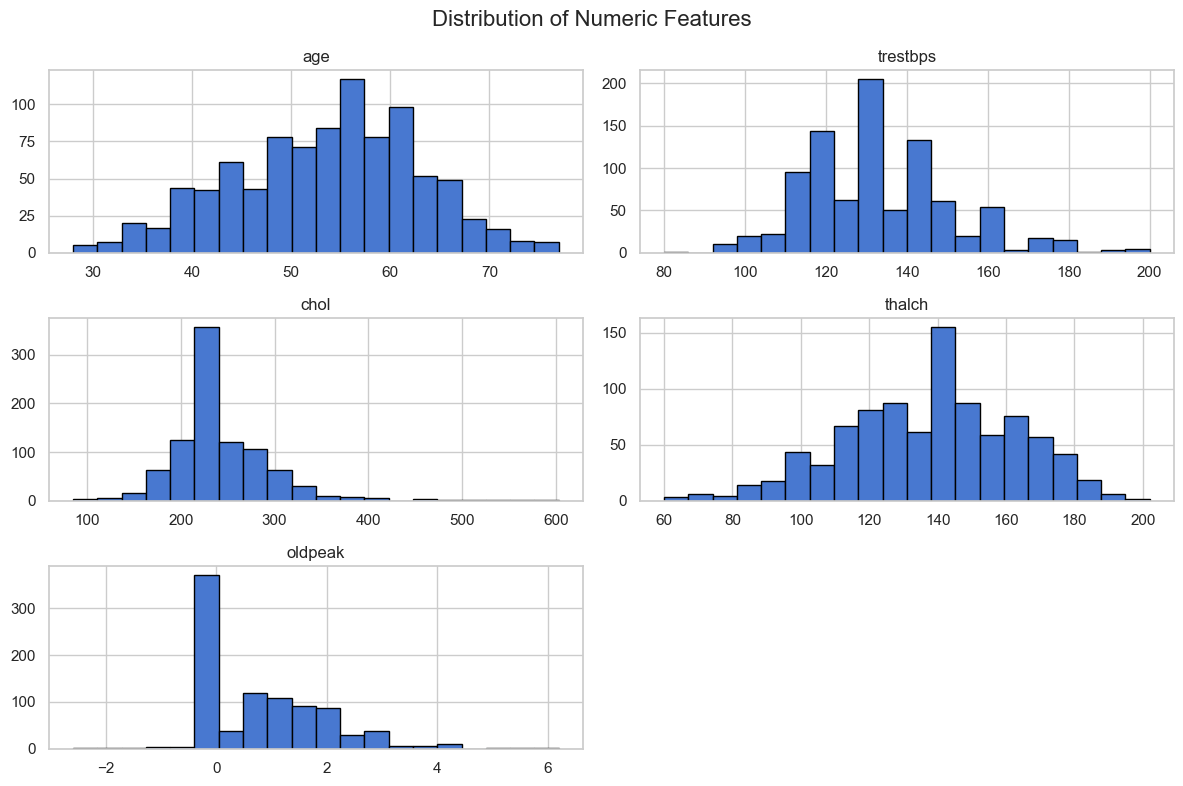

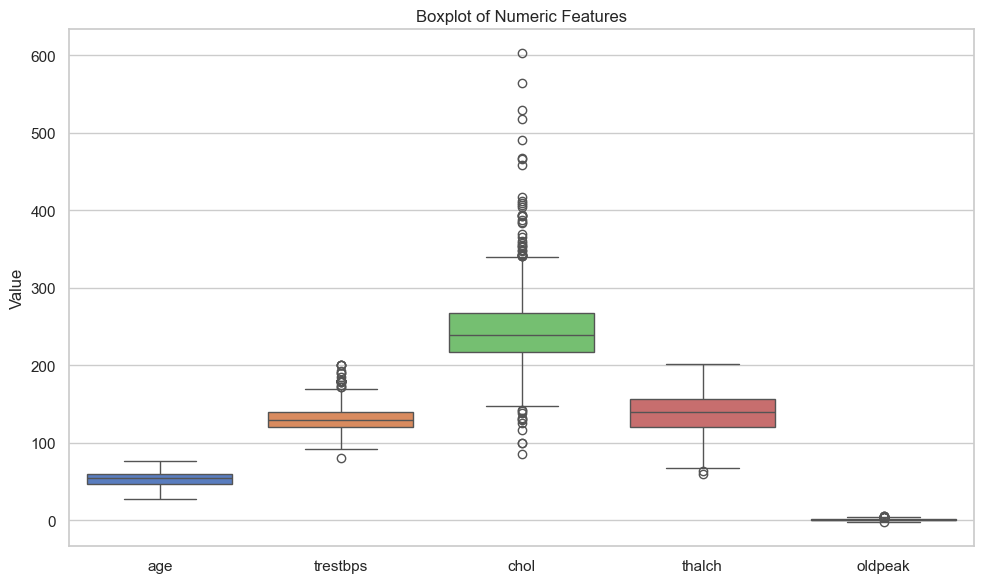

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set(style='whitegrid', palette='muted')

# Detect numeric columns
numeric_cols = df.select_dtypes(include='number').columns.tolist()

# Remove the target column
if 'target' in numeric_cols:
    numeric_cols.remove('target')

print("Numeric columns used:", numeric_cols)

# Histogram: overall distribution of numeric features
df[numeric_cols].hist(bins=20, figsize=(12, 8), edgecolor='black')
plt.suptitle('Distribution of Numeric Features', fontsize=16)
plt.tight_layout()
plt.show()

# Boxplot: visualize outliers across numeric features
plt.figure(figsize=(10, 6))
sns.boxplot(data=df[numeric_cols])
plt.title('Boxplot of Numeric Features')
plt.ylabel('Value')
plt.tight_layout()
plt.show()


### Relationship Between Features and Heart Disease

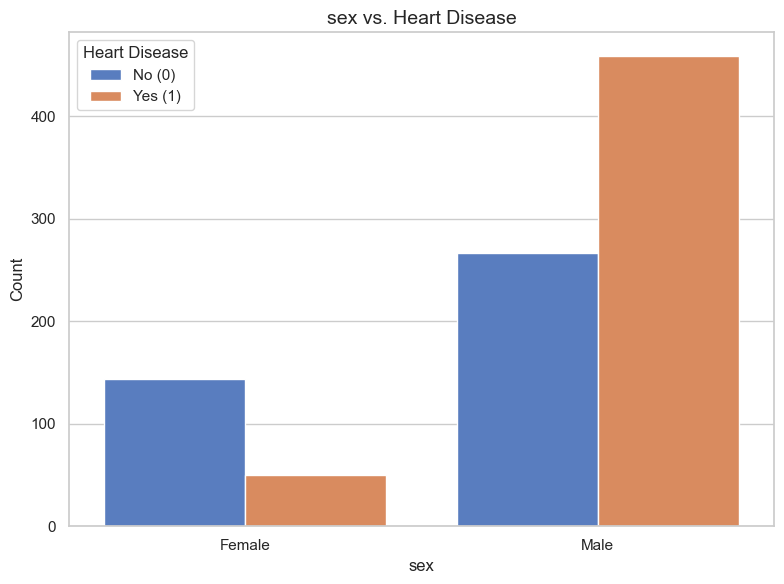

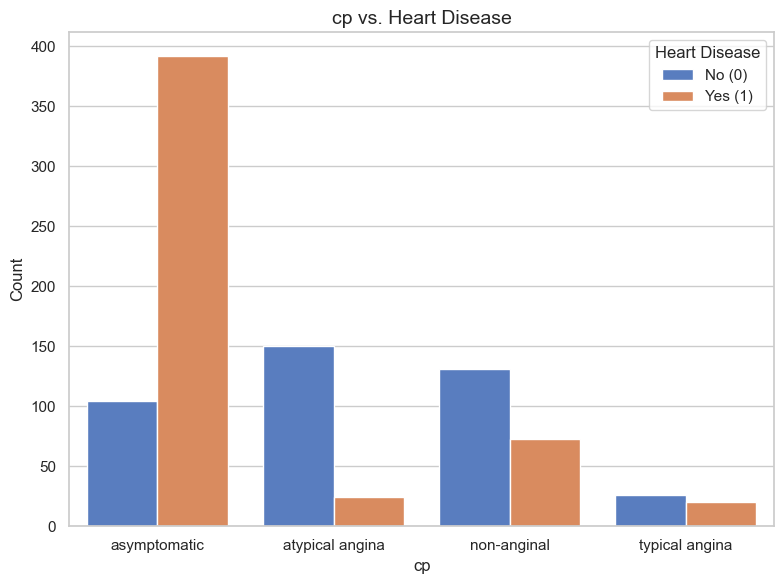

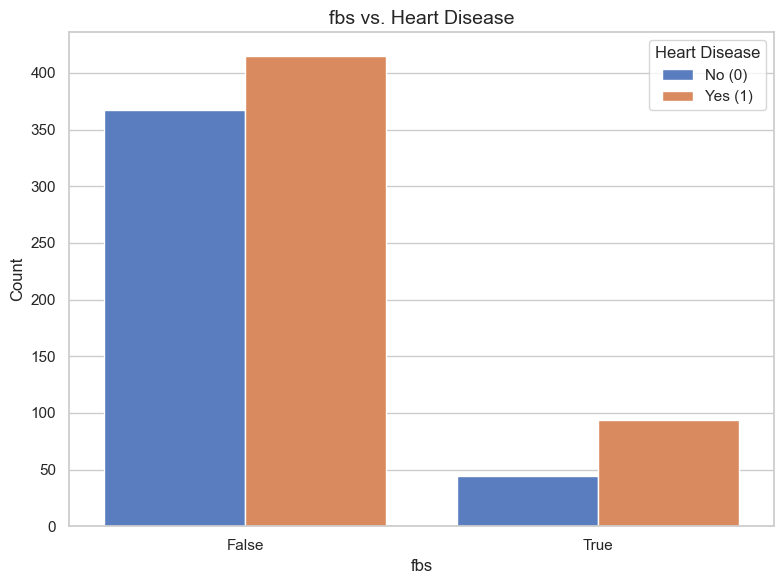

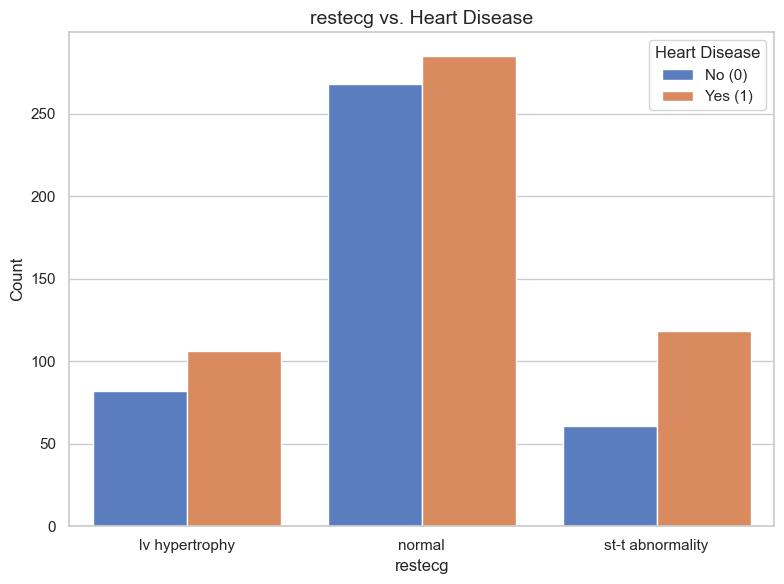

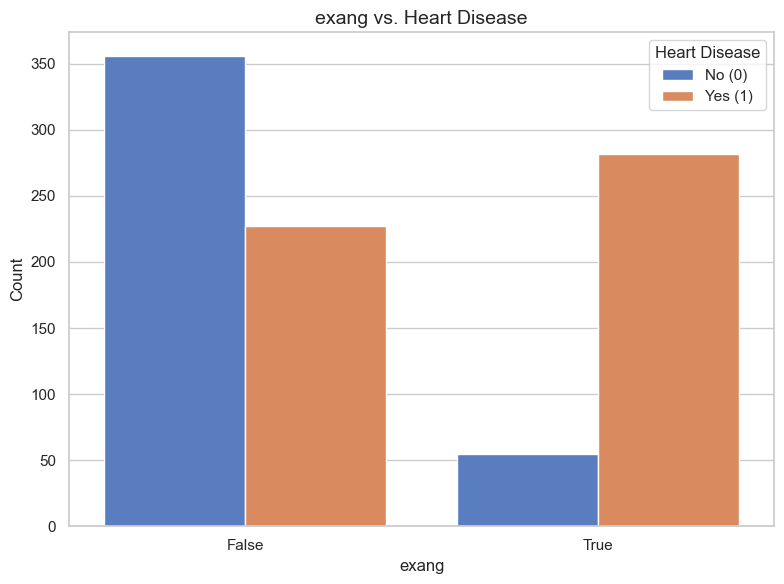

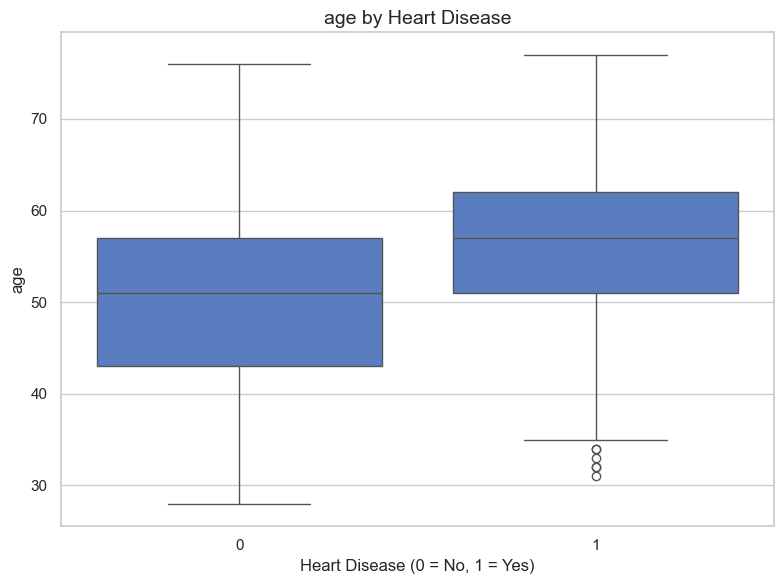

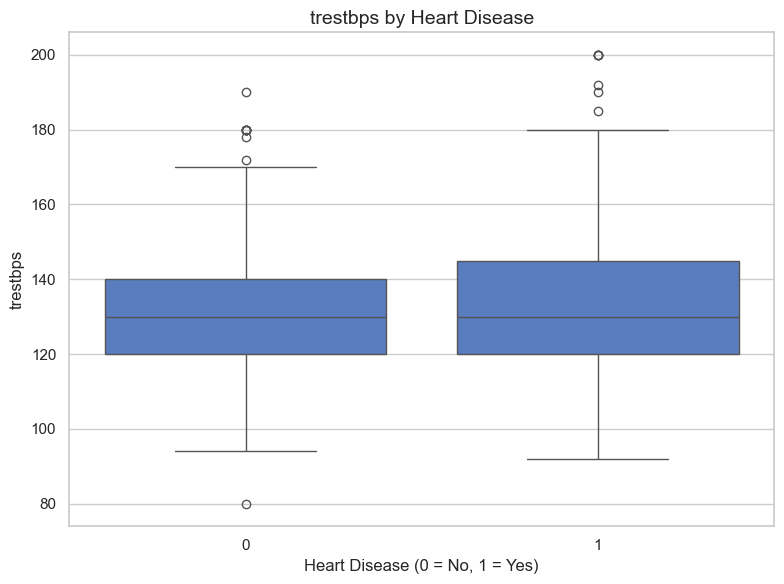

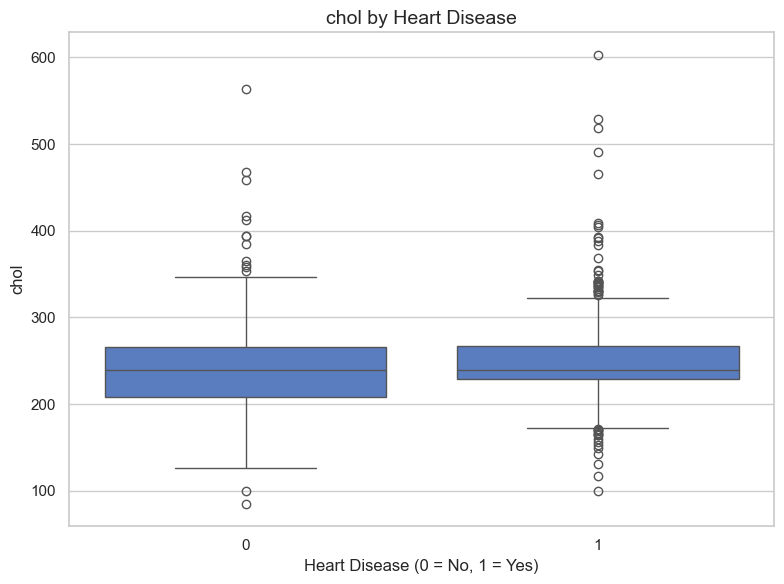

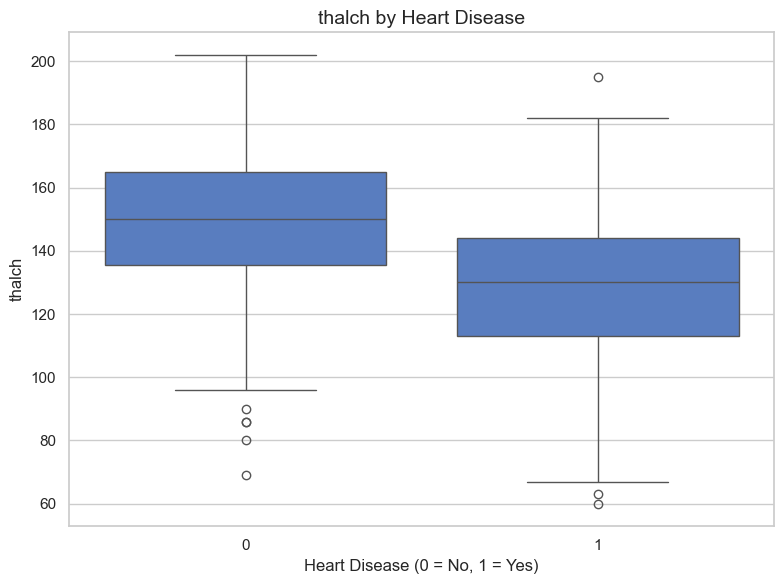

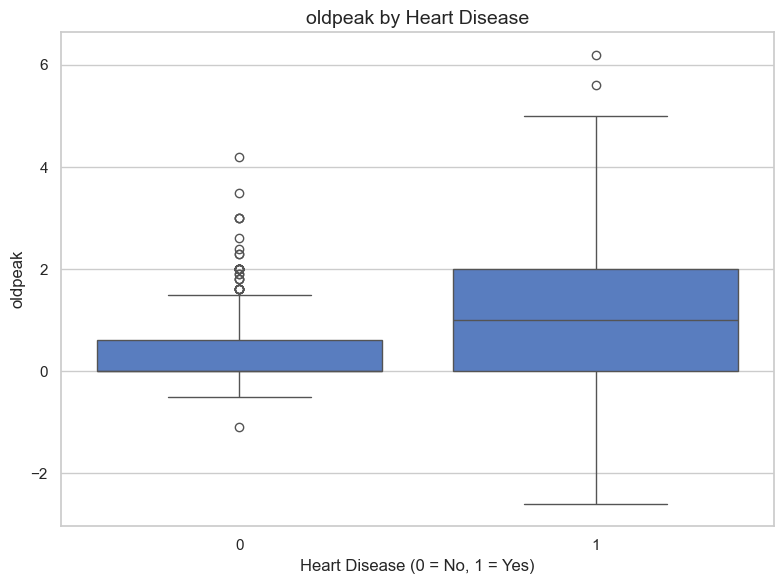

In [23]:
sns.set(style='whitegrid', palette='muted')

# Categorical features vs. target
categorical_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang']

for col in categorical_cols:
    if col in df.columns:
        plt.figure(figsize=(8,6))
        sns.countplot(x=col, hue='target', data=df)
        plt.title(f'{col} vs. Heart Disease', fontsize=14)
        plt.xlabel(col)
        plt.ylabel('Count')
        plt.legend(title='Heart Disease', labels=['No (0)', 'Yes (1)'])
        plt.tight_layout()
        plt.show()

# Numeric features vs. target
numeric_cols = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']

for col in numeric_cols:
    if col in df.columns:
        plt.figure(figsize=(8,6))
        sns.boxplot(x='target', y=col, data=df)
        plt.title(f'{col} by Heart Disease', fontsize=14)
        plt.xlabel('Heart Disease (0 = No, 1 = Yes)')
        plt.ylabel(col)
        plt.tight_layout()
        plt.show()


### Correlation Analysis

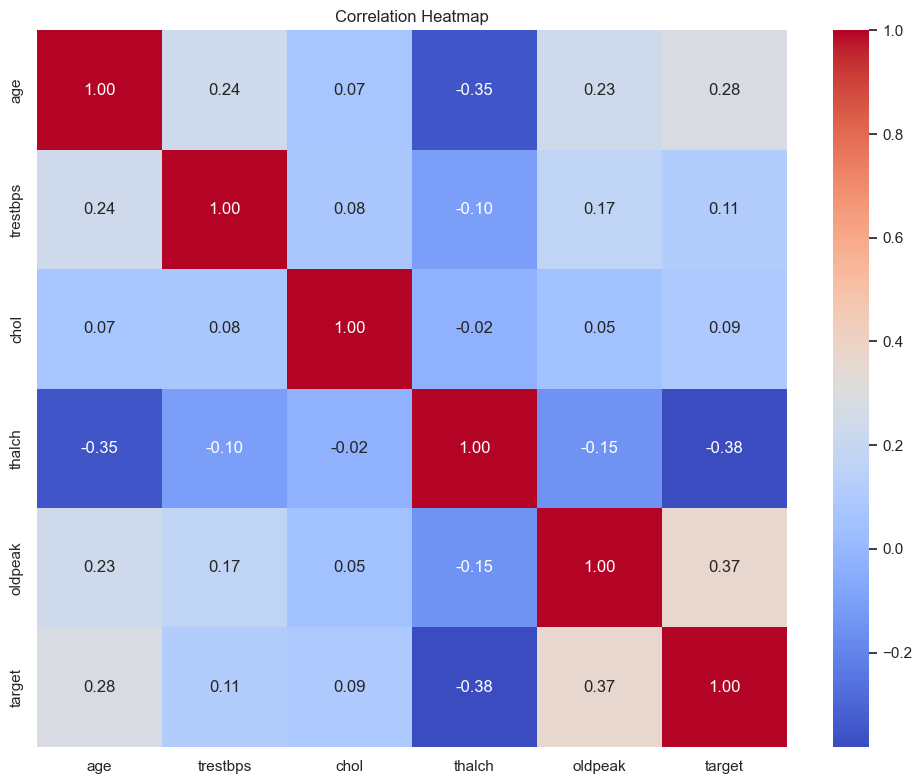

In [24]:
num_cols_for_corr = df.select_dtypes(include='number').columns.tolist()
plt.figure(figsize=(10,8))
sns.heatmap(df[num_cols_for_corr].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

# Data Mining #

In [25]:
# Import data from the Google Sheet into a pandas dataframe

import pandas as pd

sheet_id = "1uG7FBajoEwah_wVP5a4J-FOTrkTcPhrck5iuC3bawTY"
sheet_name = "heart_disease_clean"

url_part1 = f"https://docs.google.com/spreadsheets/d/{sheet_id}/"
url_part2 = f"gviz/tq?tqx=out:csv&sheet={sheet_name}"
url = url_part1 + url_part2

df = pd.read_csv(url)
print(df.head())

   age     sex    dataset               cp  trestbps   chol    fbs  \
0   63    Male  Cleveland   typical angina       145  233.0   True   
1   67    Male  Cleveland     asymptomatic       160  286.0  False   
2   67    Male  Cleveland     asymptomatic       120  229.0  False   
3   37    Male  Cleveland      non-anginal       130  250.0  False   
4   41  Female  Cleveland  atypical angina       130  204.0  False   

          restecg  thalch  exang  oldpeak  target  
0  lv hypertrophy     150  False      2.3       0  
1  lv hypertrophy     108   True      1.5       1  
2  lv hypertrophy     129   True      2.6       1  
3          normal     187  False      3.5       0  
4  lv hypertrophy     172  False      1.4       0  


# Data Transformation

In [26]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import pandas as pd

# Separate features and target
X = df.drop('target', axis=1)
y = df['target']

# Select numerical columns for scaling
numeric_cols = X.select_dtypes(include=['number']).columns

# Scale numerical features
scaler = StandardScaler()
X[numeric_cols] = scaler.fit_transform(X[numeric_cols])

# Handle categorical features (one-hot encoding)
X = pd.get_dummies(X, drop_first=True)

In [27]:
X[:5]

,age,trestbps,chol,fbs,thalch,exang,oldpeak,sex_Male,dataset_Hungary,dataset_Switzerland,dataset_VA Long Beach,cp_atypical angina,cp_non-anginal,cp_typical angina,restecg_normal,restecg_st-t abnormality
0,1.007386,0.717803,-0.236157,True,0.489727,False,1.368109,True,False,False,False,False,False,True,False,False
1,1.432034,1.554856,0.787855,False,-1.181478,True,0.611589,True,False,False,False,False,False,False,False,False
2,1.432034,-0.677285,-0.313441,False,-0.345875,True,1.651804,True,False,False,False,False,False,False,False,False
3,-1.752828,-0.119250,0.092300,False,1.961979,False,2.502889,True,False,False,False,False,True,False,True,False
4,-1.328180,-0.119250,-0.796466,False,1.365120,False,0.517024,False,False,False,False,True,False,False,False,False


# Pearson's Correlation Coefficient

In [28]:
import numpy as np
import scipy.stats

In [29]:
for col in X.columns:
  x = X[col]
  pearson_correlation_coefficient, p_value_pearson = scipy.stats.pearsonr(x, y)
  print(f"Correlation between {col} and heart disease: ", pearson_correlation_coefficient)

Correlation between age and heart disease:  0.28269958016942376
Correlation between trestbps and heart disease:  0.11130491907796042
Correlation between chol and heart disease:  0.08900839431083118
Correlation between fbs and heart disease:  0.1080711605391424
Correlation between thalch and heart disease:  -0.3818638086876135
Correlation between exang and heart disease:  0.43360514748448203
Correlation between oldpeak and heart disease:  0.3661383918111457
Correlation between sex_Male and heart disease:  0.3072844284149284
Correlation between dataset_Hungary and heart disease:  -0.2632966763077582
Correlation between dataset_Switzerland and heart disease:  0.3016142462041657
Correlation between dataset_VA Long Beach and heart disease:  0.20326730460269682
Correlation between cp_atypical angina and heart disease:  -0.4034654635744246
Correlation between cp_non-anginal and heart disease:  -0.20981211761410085
Correlation between cp_typical angina and heart disease:  -0.05467262111745493


The column 'exang' had the highest positive correlation, which represents whether the person has exercise-induced angina. The column 'oldpeak' had the second highest positive correlation, which represents ST depression induced by exercise relative to rest. The column 'cp_atypical angina' had the highest negative correlation, which represents having atypical angina for chest pain. The column 'thalch' had the second to highest negative correlation, which represents maximum heart rate achieved.

# Apriori Association

In [30]:
df_apriori = df[['exang', 'cp']]

In [31]:
for col in df_apriori.columns:
    print(f"Column '{col}':")
    print(df_apriori[col].value_counts())
    print("\n")

Column 'exang':
exang
False    583
True     337
Name: count, dtype: int64


Column 'cp':
cp
asymptomatic       496
non-anginal        204
atypical angina    174
typical angina      46
Name: count, dtype: int64




In [32]:
from mlxtend.preprocessing import TransactionEncoder
te = TransactionEncoder()

# Convert boolean column to string before passing to TransactionEncoder
df_apriori['exang'] = df_apriori['exang'].astype(str)

# Convert the DataFrame to the required format for TransactionEncoder
# Each row is a list of items (non-null values)
transactions = df_apriori.apply(lambda x: x.dropna().tolist(), axis=1).tolist()

angina_chest_pain_array = te.fit(transactions).transform(transactions)
angina_chest_pain_array

/var/folders/q7/h_6gjcw11rv2jq40fcjwcf2r0000gn/T/ipykernel_98039/309637405.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_apriori['exang'] = df_apriori['exang'].astype(str)


array([[ True, False, False, False, False,  True],
       [False,  True,  True, False, False, False],
       [False,  True,  True, False, False, False],
       ...,
       [ True, False,  True, False, False, False],
       [ True, False,  True, False, False, False],
       [False,  True, False,  True, False, False]])

In [33]:
import pandas as pd
angina_chest_pain_df = pd.DataFrame(angina_chest_pain_array, columns = te.columns_)
angina_chest_pain_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   False            920 non-null    bool 
 1   True             920 non-null    bool 
 2   asymptomatic     920 non-null    bool 
 3   atypical angina  920 non-null    bool 
 4   non-anginal      920 non-null    bool 
 5   typical angina   920 non-null    bool 
dtypes: bool(6)
memory usage: 5.5 KB


In [34]:
from mlxtend.frequent_patterns import apriori, association_rules

# Convert the boolean array back to a DataFrame with original column names
angina_chest_pain_df = pd.DataFrame(angina_chest_pain_array, columns = te.columns_)

# Perform Apriori analysis
frequent_itemsets = apriori(angina_chest_pain_df, min_support=0.3, use_colnames=True)

# Display frequent itemsets
display(frequent_itemsets)

,support,itemsets
0,0.633696,(False)
1,0.366304,(True)
2,0.539130,(asymptomatic)
3,0.300000,"(asymptomatic, True)"


With the Apriori association, we found that being asymptomatic of angina and having exercise-induced angina had a support of 30% across all rows. Not having exercise-induced angina had a support of 63.3% across all rows.

# Classification (Original Features)

In [35]:
from sklearn.model_selection import train_test_split

# Split data into training and testing sets using original features
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Naive Bayes (NB)

In [36]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import pandas as pd

# Split data into training and testing sets
# Using the X_train, X_test, y_train, y_test from the previous cell (original features)

# Initialize and train the Naive Bayes classifier
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = nb_model.predict(X_test)

# Evaluate the model
nb_accuracy = accuracy_score(y_test, y_pred)
nb_precision = precision_score(y_test, y_pred)
nb_recall = recall_score(y_test, y_pred)
nb_f1 = f1_score(y_test, y_pred)
nb_confusion_mat = confusion_matrix(y_test, y_pred)

print(f"Naive Bayes Accuracy: {nb_accuracy:.4f}")
print(f"Naive Bayes Precision: {nb_precision:.4f}")
print(f"Naive Bayes Recall: {nb_recall:.4f}")
print(f"Naive Bayes F1-score: {nb_f1:.4f}")
print("\nNaive Bayes Confusion Matrix:")
print(nb_confusion_mat)

Naive Bayes Accuracy: 0.8043
Naive Bayes Precision: 0.8842
Naive Bayes Recall: 0.7706
Naive Bayes F1-score: 0.8235

Naive Bayes Confusion Matrix:
[[64 11]
 [25 84]]


## Support Vector Machine (SVM)

In [37]:
from sklearn.svm import SVC

# Initialize and train the SVM classifier
svm_model = SVC(kernel='linear', random_state=42)
svm_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_svm = svm_model.predict(X_test)

# Evaluate the model
svm_accuracy = accuracy_score(y_test, y_pred_svm)
svm_precision = precision_score(y_test, y_pred_svm)
svm_recall = recall_score(y_test, y_pred_svm)
svm_f1 = f1_score(y_test, y_pred_svm)
svm_confusion_mat = confusion_matrix(y_test, y_pred_svm)

print(f"SVM Accuracy: {svm_accuracy:.4f}")
print(f"SVM Precision: {svm_precision:.4f}")
print(f"SVM Recall: {svm_recall:.4f}")
print(f"SVM F1-score: {svm_f1:.4f}")
print("\nSVM Confusion Matrix:")
print(svm_confusion_mat)

SVM Accuracy: 0.8261
SVM Precision: 0.8598
SVM Recall: 0.8440
SVM F1-score: 0.8519

SVM Confusion Matrix:
[[60 15]
 [17 92]]


## Random Forest (RF)

In [38]:
from sklearn.ensemble import RandomForestClassifier

# Initialize and train the Random Forest classifier
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_rf = rf_model.predict(X_test)

# Evaluate the model
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_confusion_mat = confusion_matrix(y_test, y_pred_rf)

print(f"Random Forest Accuracy: {rf_accuracy:.4f}")
print(f"Random Forest Precision: {rf_precision:.4f}")
print(f"Random Forest Recall: {rf_recall:.4f}")
print(f"Random Forest F1-score: {rf_f1:.4f}")
print("\nRandom Forest Confusion Matrix:")
print(rf_confusion_mat)

Random Forest Accuracy: 0.8152
Random Forest Precision: 0.8641
Random Forest Recall: 0.8165
Random Forest F1-score: 0.8396

Random Forest Confusion Matrix:
[[61 14]
 [20 89]]


## XGBoost (XGB)

In [39]:
from xgboost import XGBClassifier

# Initialize and train the XGBoost classifier
xgb_model = XGBClassifier(random_state=42)
xgb_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_xgb = xgb_model.predict(X_test)

# Evaluate the model
xgb_accuracy = accuracy_score(y_test, y_pred_xgb)
xgb_precision = precision_score(y_test, y_pred_xgb)
xgb_recall = recall_score(y_test, y_pred_xgb)
xgb_f1 = f1_score(y_test, y_pred_xgb)
xgb_confusion_mat = confusion_matrix(y_test, y_pred_xgb)

print(f"XGBoost Accuracy: {xgb_accuracy:.4f}")
print(f"XGBoost Precision: {xgb_precision:.4f}")
print(f"XGBoost Recall: {xgb_recall:.4f}")
print(f"XGBoost F1-score: {xgb_f1:.4f}")
print("\nXGBoost Confusion Matrix:")
print(xgb_confusion_mat)

XGBoost Accuracy: 0.8424
XGBoost Precision: 0.9000
XGBoost Recall: 0.8257
XGBoost F1-score: 0.8612

XGBoost Confusion Matrix:
[[65 10]
 [19 90]]


## Evaluation

In [40]:
import pandas as pd

# Create a dictionary to store the evaluation metrics for each model
evaluation_metrics = {
    'Naive Bayes': {
        'Accuracy': nb_accuracy,
        'Precision': nb_precision,
        'Recall': nb_recall,
        'F1-score': nb_f1
    },
    'SVM': {
        'Accuracy': svm_accuracy,
        'Precision': svm_precision,
        'Recall': svm_recall,
        'F1-score': svm_f1
    },
    'Random Forest': {
        'Accuracy': rf_accuracy,
        'Precision': rf_precision,
        'Recall': rf_recall,
        'F1-score': rf_f1
    },
    'XGBoost': {
        'Accuracy': xgb_accuracy,
        'Precision': xgb_precision,
        'Recall': xgb_recall,
        'F1-score': xgb_f1
    },
}

# Display the evaluation DataFrame
evaluation_df = pd.DataFrame(evaluation_metrics).T
display(evaluation_df)

,Accuracy,Precision,Recall,F1-score
Naive Bayes,0.804348,0.884211,0.770642,0.823529
SVM,0.826087,0.859813,0.844037,0.851852
Random Forest,0.815217,0.864078,0.816514,0.839623
XGBoost,0.842391,0.900000,0.825688,0.861244


# Data Visualization (Result Focused - Original Features Based)

###Model Performance Comparison

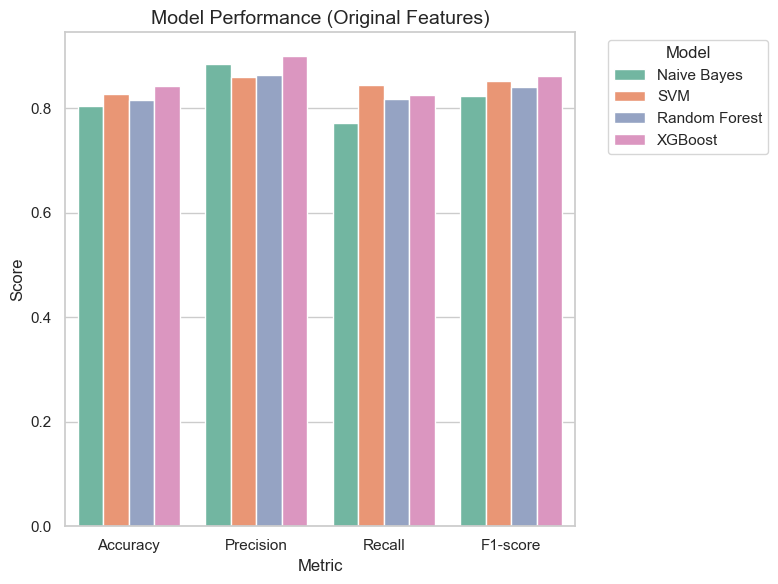

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming evaluation_df from earlier cells exists
plt.figure(figsize=(8,6))
sns.barplot(
    data=evaluation_df.reset_index().melt(id_vars='index', var_name='Metric', value_name='Score'),
    x='Metric', y='Score', hue='index', palette='Set2'
)
plt.title('Model Performance (Original Features)', fontsize=14)
plt.ylabel('Score')
plt.xlabel('Metric')
plt.legend(title='Model', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

###Confusion Matrices for Each Model

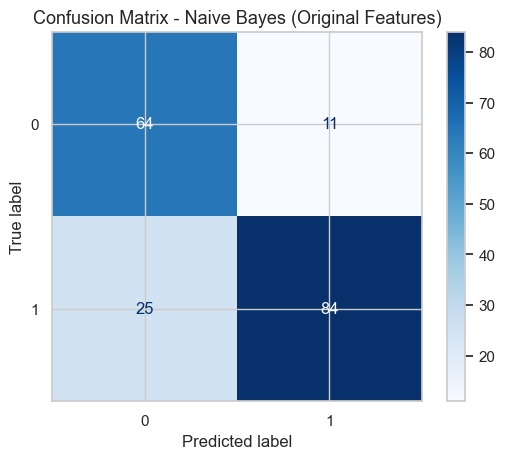

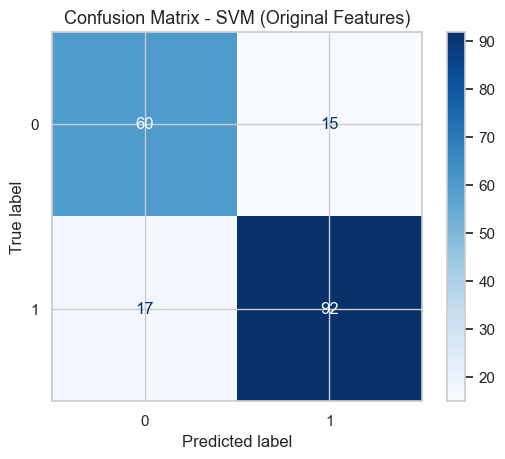

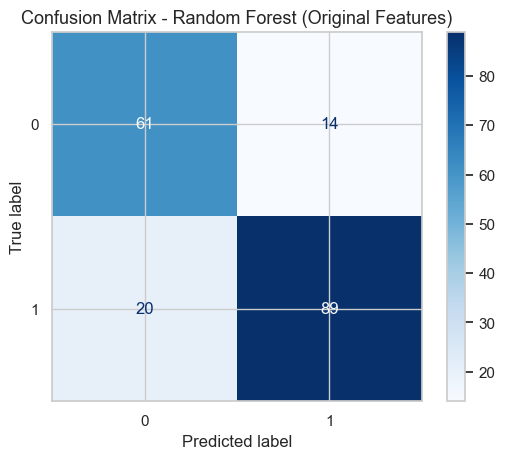

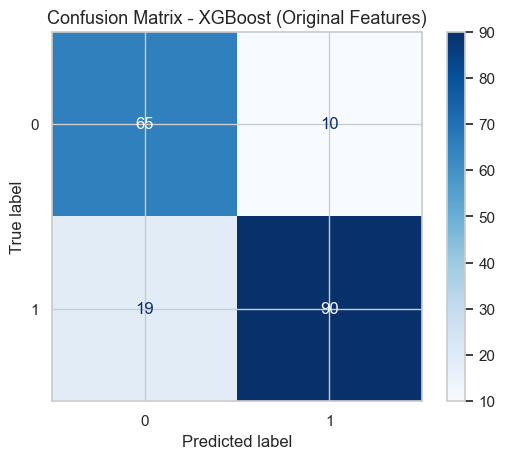

In [42]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

models_conf_mats = {
    'Naive Bayes': nb_confusion_mat,
    'SVM': svm_confusion_mat,
    'Random Forest': rf_confusion_mat,
    'XGBoost': xgb_confusion_mat
}

for name, cm in models_conf_mats.items():
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(cmap='Blues', values_format='d')
    plt.title(f'Confusion Matrix - {name} (Original Features)', fontsize=13)
    plt.show()

###ROC-AUC Curves

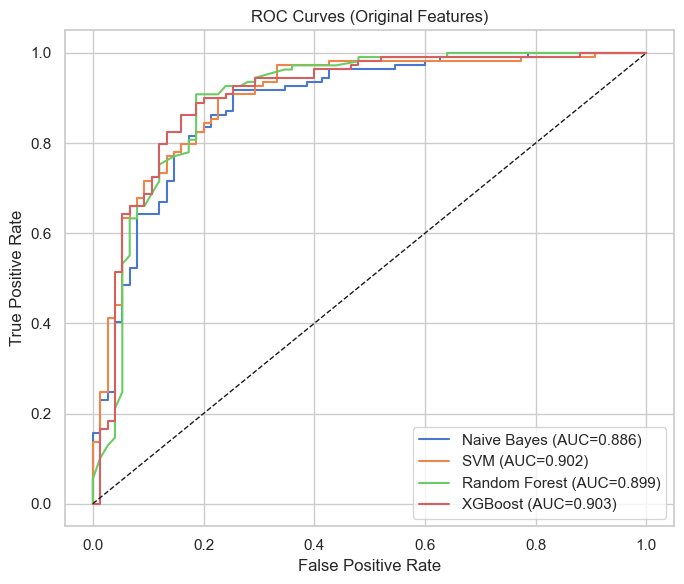

In [43]:
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(7,6))

# Naive Bayes
nb_score = nb_model.predict_proba(X_test)[:,1]
fpr, tpr, _ = roc_curve(y_test, nb_score); auc_nb = roc_auc_score(y_test, nb_score)
plt.plot(fpr, tpr, label=f'Naive Bayes (AUC={auc_nb:.3f})')

# SVM (linear) - decision_function 사용
svm_score = svm_model.decision_function(X_test)
fpr, tpr, _ = roc_curve(y_test, svm_score); auc_svm = roc_auc_score(y_test, svm_score)
plt.plot(fpr, tpr, label=f'SVM (AUC={auc_svm:.3f})')

# Random Forest
rf_score = rf_model.predict_proba(X_test)[:,1]
fpr, tpr, _ = roc_curve(y_test, rf_score); auc_rf = roc_auc_score(y_test, rf_score)
plt.plot(fpr, tpr, label=f'Random Forest (AUC={auc_rf:.3f})')

# XGBoost
xgb_score = xgb_model.predict_proba(X_test)[:,1]
fpr, tpr, _ = roc_curve(y_test, xgb_score); auc_xgb = roc_auc_score(y_test, xgb_score)
plt.plot(fpr, tpr, label=f'XGBoost (AUC={auc_xgb:.3f})')

plt.plot([0,1],[0,1],'k--', linewidth=1)
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curves (Original Features)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


###Precision-Recall Curves

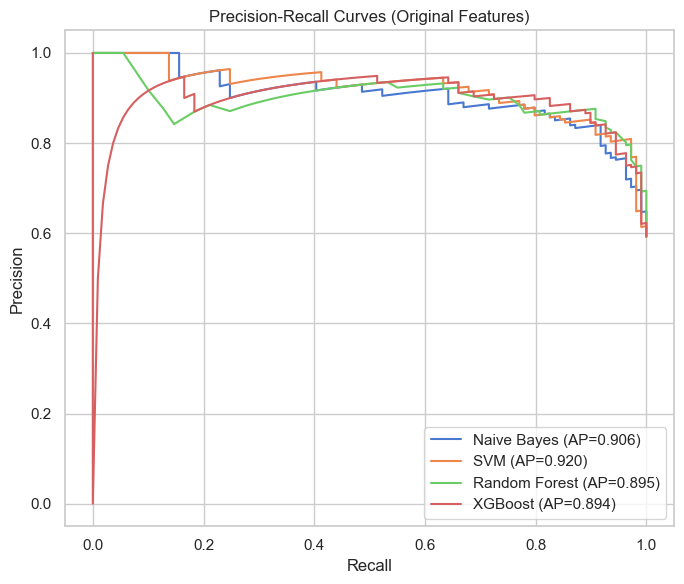

In [44]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(7,6))

def pr_plot(scores, name):
    p, r, _ = precision_recall_curve(y_test, scores)
    ap = average_precision_score(y_test, scores)
    plt.plot(r, p, label=f'{name} (AP={ap:.3f})')

pr_plot(nb_score, 'Naive Bayes')
pr_plot(svm_score, 'SVM')
pr_plot(rf_score, 'Random Forest')
pr_plot(xgb_score, 'XGBoost')

plt.xlabel('Recall'); plt.ylabel('Precision')
plt.title('Precision-Recall Curves (Original Features)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


###Top Feature Importances (RF / XGB)

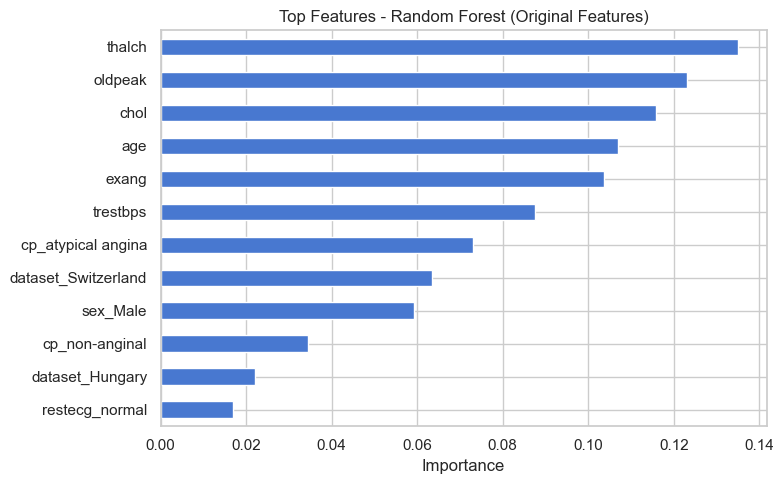

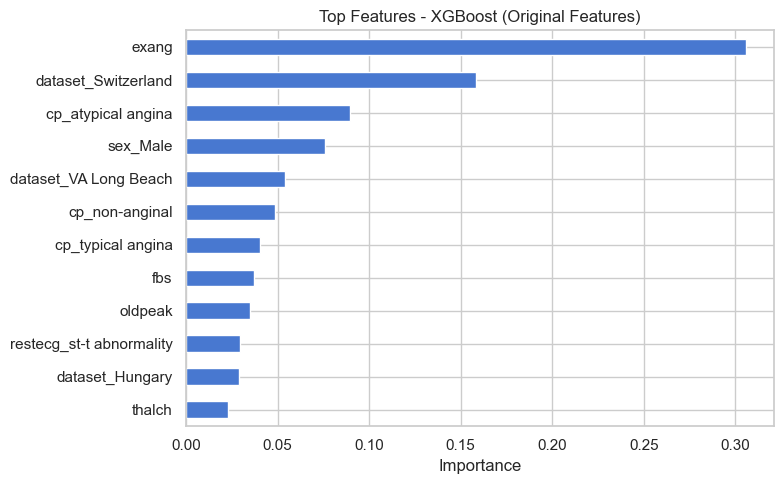

In [45]:
def plot_top_importances(model, X, title, k=12):
    importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)[:k]
    plt.figure(figsize=(8,5))
    importances.iloc[::-1].plot(kind='barh')
    plt.title(title); plt.xlabel('Importance'); plt.tight_layout(); plt.show()
    return importances

rf_top = plot_top_importances(rf_model, X, 'Top Features - Random Forest (Original Features)', k=12)
xgb_top = plot_top_importances(xgb_model, X, 'Top Features - XGBoost (Original Features)', k=12)


# Cross-Validation

In [46]:
# Cross-Validation (Original Features)
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import numpy as np
import pandas as pd

# Helper: ensure purely numeric matrix (NB/SVM handle bools but we'll make it explicit)
X_cv = X.copy()
for col in X_cv.columns:
    if X_cv[col].dtype == bool:
        X_cv[col] = X_cv[col].astype(int)

# Define models
models = {
    "Naive Bayes": GaussianNB(),
    "SVM (linear)": SVC(kernel="linear", probability=True, random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42, eval_metric="logloss")
}

NUM_OF_SPLITS = 5

# CV setup & metrics
cv = StratifiedKFold(n_splits=NUM_OF_SPLITS, shuffle=True, random_state=42)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

# Run cross-validate for each model
cv_summaries = {}
raw_cv_results = {}

for name, clf in models.items():
    scores = cross_validate(
        clf, X_cv, y,
        cv=cv,
        scoring=scoring,
        return_train_score=False,
        n_jobs=-1
    )
    raw_cv_results[name] = scores  # keep for later digging (e.g., per-fold)
    # Summarize mean ± std for display
    cv_summaries[name] = {
        "Accuracy": f"{scores['test_accuracy'].mean():.4f} ± {scores['test_accuracy'].std():.4f}",
        "Precision": f"{scores['test_precision'].mean():.4f} ± {scores['test_precision'].std():.4f}",
        "Recall": f"{scores['test_recall'].mean():.4f} ± {scores['test_recall'].std():.4f}",
        "F1-score": f"{scores['test_f1'].mean():.4f} ± {scores['test_f1'].std():.4f}",
        "ROC AUC": f"{scores['test_roc_auc'].mean():.4f} ± {scores['test_roc_auc'].std():.4f}",
    }

# Neat table (sorted by F1-score)
cv_df = pd.DataFrame(cv_summaries).T
order = (
    pd.Series({m: np.mean(raw_cv_results[m]["test_f1"]) for m in raw_cv_results})
    .sort_values(ascending=False)
    .index
)
cv_df = cv_df.loc[order]
display(cv_df)

,Accuracy,Precision,Recall,F1-score,ROC AUC
Random Forest,0.8185 ± 0.0170,0.8276 ± 0.0116,0.8487 ± 0.0294,0.8378 ± 0.0171,0.8798 ± 0.0197
SVM (linear),0.8152 ± 0.0158,0.8294 ± 0.0125,0.8390 ± 0.0352,0.8337 ± 0.0170,0.8971 ± 0.0118
Naive Bayes,0.8163 ± 0.0226,0.8495 ± 0.0131,0.8114 ± 0.0344,0.8298 ± 0.0232,0.8848 ± 0.0186
XGBoost,0.7946 ± 0.0193,0.8031 ± 0.0158,0.8331 ± 0.0288,0.8176 ± 0.0185,0.8608 ± 0.0230


In [47]:
# also keep numeric means for later selection in tuning step
cv_means_df = pd.DataFrame({
    name: {
        "accuracy": raw["test_accuracy"].mean(),
        "precision": raw["test_precision"].mean(),
        "recall": raw["test_recall"].mean(),
        "f1": raw["test_f1"].mean(),
        "roc_auc": raw["test_roc_auc"].mean(),
    }
    for name, raw in raw_cv_results.items()
}).T

# You can display this too if you like numeric-only view:
display(cv_means_df.sort_values('f1', ascending=False))

,accuracy,precision,recall,f1,roc_auc
Random Forest,0.818478,0.827621,0.848748,0.837816,0.879773
SVM (linear),0.815217,0.829430,0.838963,0.833691,0.897080
Naive Bayes,0.816304,0.849513,0.811357,0.829800,0.884844
XGBoost,0.794565,0.803120,0.833062,0.817589,0.860754


## Hyperparameter-Tuning

In [48]:
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from scipy.stats import loguniform, uniform, randint
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score, roc_auc_score, accuracy_score
import numpy as np
import pandas as pd

# Helpers for tuning and summarizing
def run_cv_summary(model, X, y, cv, scoring):
    """Return (summary_dict, raw_scores) using cross_validate-like metrics for a fitted estimator."""
    from sklearn.model_selection import cross_validate
    scores = cross_validate(model, X, y, cv=cv, scoring=scoring, n_jobs=-1, return_train_score=False)
    summary = {
        "Accuracy": f"{scores['test_accuracy'].mean():.3f} ± {scores['test_accuracy'].std():.3f}",
        "Precision": f"{scores['test_precision'].mean():.3f} ± {scores['test_precision'].std():.3f}",
        "Recall": f"{scores['test_recall'].mean():.3f} ± {scores['test_recall'].std():.3f}",
        "F1": f"{scores['test_f1'].mean():.3f} ± {scores['test_f1'].std():.3f}",
        "ROC AUC": f"{scores['test_roc_auc'].mean():.3f} ± {scores['test_roc_auc'].std():.3f}",
    }
    return summary, scores

def randomized_tune(name, estimator, param_distributions, X, y, *, n_iter=40, cv=None, scoring=None, refit_metric="f1", random_state=42):
    """Run RandomizedSearchCV and return dict with best_estimator, best_params, cv_results_ (DataFrame), and best_scores summary."""
    search = RandomizedSearchCV(
        estimator=estimator,
        param_distributions=param_distributions,
        n_iter=n_iter,
        scoring=scoring,
        refit=refit_metric,
        cv=cv,
        n_jobs=-1,
        random_state=random_state,
        verbose=0
    )
    search.fit(X, y)
    # Re-evaluate best estimator across metrics for a clean summary
    best_summary, raw = run_cv_summary(search.best_estimator_, X, y, cv=cv, scoring=scoring)
    return {
        "name": name,
        "search": search,
        "best_estimator": search.best_estimator_,
        "best_params": search.best_params_,
        "best_summary": best_summary,
        "raw_scores": raw,
        "cv_results_df": pd.DataFrame(search.cv_results_)
    }

# Reuse the same CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "accuracy": make_scorer(accuracy_score),
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": make_scorer(roc_auc_score),
}
refit_metric = "f1"

# Ensure numeric matrix for tree/boosting models (SVM will scale inside pipeline)
X_tune = X.copy()
for col in X_tune.columns:
    if X_tune[col].dtype == bool:
        X_tune[col] = X_tune[col].astype(int)

### SVM

In [49]:
# SVM (linear & RBF)
svm_linear_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="linear", probability=True, random_state=42))
])
svm_linear_space = {
    "svc__C": loguniform(1e-3, 1e3),
    "svc__class_weight": [None, "balanced"]
}
svm_linear_res = randomized_tune(
    "SVM (linear)",
    svm_linear_pipe,
    svm_linear_space,
    X_tune, y,
    n_iter=40,
    cv=cv,
    scoring=scoring,
    refit_metric=refit_metric,
    random_state=42
)

svm_rbf_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="rbf", probability=True, random_state=42))
])
svm_rbf_space = {
    "svc__C": loguniform(1e-3, 1e3),
    "svc__gamma": loguniform(1e-4, 1e1),
    "svc__class_weight": [None, "balanced"]
}
svm_rbf_res = randomized_tune(
    "SVM (rbf)",
    svm_rbf_pipe,
    svm_rbf_space,
    X_tune, y,
    n_iter=60,  # extra iters for gamma dimension
    cv=cv,
    scoring=scoring,
    refit_metric=refit_metric,
    random_state=42
)

# Pick the better SVM by mean CV F1
svm_linear_f1 = np.mean(svm_linear_res["raw_scores"]["test_f1"])
svm_rbf_f1 = np.mean(svm_rbf_res["raw_scores"]["test_f1"])
svm_best_res = svm_rbf_res if svm_rbf_f1 >= svm_linear_f1 else svm_linear_res
svm_best = svm_best_res["best_estimator"]

### Random Forest

In [50]:
# Random Forest
rf = RandomForestClassifier(random_state=42)
rf_space = {
    "n_estimators": randint(100, 800),
    "max_depth": randint(2, 30),
    "min_samples_split": randint(2, 20),
    "min_samples_leaf": randint(1, 20),
    "max_features": ["sqrt", "log2", None],
    "bootstrap": [True, False],
    "class_weight": [None, "balanced", "balanced_subsample"]
}
rf_res = randomized_tune(
    "Random Forest",
    rf,
    rf_space,
    X_tune, y,
    n_iter=80,
    cv=cv,
    scoring=scoring,
    refit_metric=refit_metric,
    random_state=42
)
rf_best = rf_res["best_estimator"]

### XGBoost

In [51]:
# XGBoost
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="xgboost")

xgb = XGBClassifier(
    random_state=42,
    eval_metric="logloss",  # keep explicit eval_metric, no label encoder
)

xgb_space = {
    "n_estimators": randint(200, 1200),
    "max_depth": randint(2, 12),
    "learning_rate": loguniform(1e-3, 3e-1),
    "subsample": uniform(0.5, 0.5),
    "colsample_bytree": uniform(0.5, 0.5),
    "min_child_weight": randint(1, 10),
    "gamma": loguniform(1e-8, 1e0),
    "reg_lambda": loguniform(1e-3, 1e2)
}
xgb_res = randomized_tune(
    "XGBoost",
    xgb,
    xgb_space,
    X_tune, y,
    n_iter=120,
    cv=cv,
    scoring=scoring,
    refit_metric=refit_metric,
    random_state=42
)
xgb_best = xgb_res["best_estimator"]

### Summary

In [52]:
# ==== Summaries & selection table ====
tuned_sets = [svm_best_res, rf_res, xgb_res]

best_rows = []
numeric_f1_for_sort = {}
for r in tuned_sets:
    name = r["name"] + " (tuned)"
    summ = r["best_summary"]
    best_rows.append({"Model": name, **summ})
    numeric_f1_for_sort[name] = float(np.mean(r["raw_scores"]["test_f1"]))

tuned_cv_df = pd.DataFrame(best_rows).set_index("Model").loc[
    pd.Series(numeric_f1_for_sort).sort_values(ascending=False).index
]
display(tuned_cv_df)

# Persist best estimators for next steps (or later use)
try:
    fitted_models
except NameError:
    fitted_models = {}

fitted_models["SVM (tuned)"] = svm_best
fitted_models["Random Forest (tuned)"] = rf_best
fitted_models["XGBoost (tuned)"] = xgb_best

evaluation_metrics = {}
for r in tuned_sets:
    name = r["name"] + " (tuned)"
    evaluation_metrics[name] = {
        "accuracy": float(np.mean(r["raw_scores"]["test_accuracy"])),
        "precision": float(np.mean(r["raw_scores"]["test_precision"])),
        "recall": float(np.mean(r["raw_scores"]["test_recall"])),
        "f1": float(np.mean(r["raw_scores"]["test_f1"])),
        "roc_auc": float(np.mean(r["raw_scores"]["test_roc_auc"])),
        "params": r["best_params"]
    }

# peek at hyperparameters
pd.DataFrame({k: v["params"] for k, v in evaluation_metrics.items()}).T

,Accuracy,Precision,Recall,F1,ROC AUC
XGBoost (tuned),0.832 ± 0.011,0.828 ± 0.014,0.878 ± 0.022,0.852 ± 0.010,0.826 ± 0.011
SVM (rbf) (tuned),0.824 ± 0.021,0.814 ± 0.012,0.884 ± 0.029,0.847 ± 0.019,0.817 ± 0.020
Random Forest (tuned),0.825 ± 0.022,0.827 ± 0.017,0.864 ± 0.030,0.845 ± 0.020,0.820 ± 0.021


,svc__C,svc__class_weight,svc__gamma,bootstrap,class_weight,max_depth,max_features,min_samples_leaf,min_samples_split,n_estimators,colsample_bytree,gamma,learning_rate,min_child_weight,reg_lambda,subsample
SVM (rbf) (tuned),0.292565,NaN,0.002473,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Random Forest (tuned),NaN,NaN,NaN,True,None,7,sqrt,2,7,610,NaN,NaN,NaN,NaN,NaN,NaN
XGBoost (tuned),NaN,NaN,NaN,NaN,NaN,4.0,NaN,NaN,NaN,234.0,0.636981,0.000001,0.0086,2.0,0.048169,0.827861


## Evaluate


SVM (tuned) performance:
 Accuracy : 0.859
 Precision: 0.867
 Recall   : 0.899
 F1-score : 0.883
 ROC AUC  : 0.913


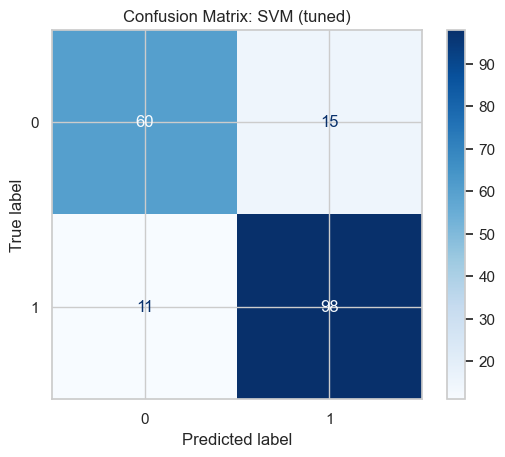


Random Forest (tuned) performance:
 Accuracy : 0.924
 Precision: 0.920
 Recall   : 0.954
 F1-score : 0.937
 ROC AUC  : 0.963


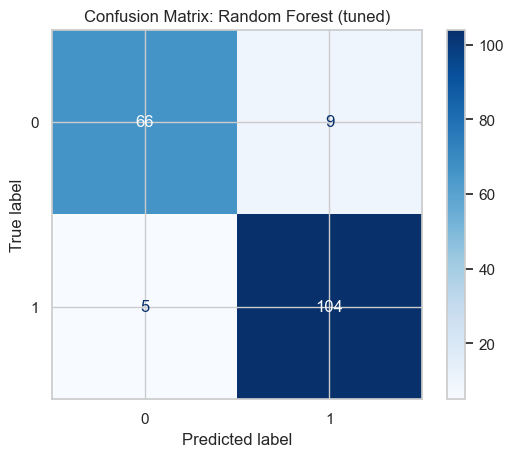


XGBoost (tuned) performance:
 Accuracy : 0.886
 Precision: 0.893
 Recall   : 0.917
 F1-score : 0.905
 ROC AUC  : 0.943


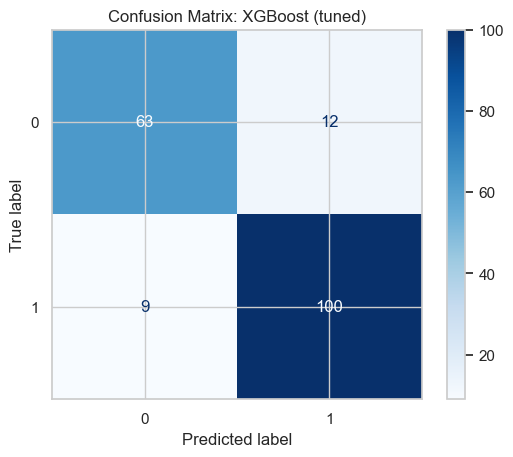

,accuracy,precision,recall,f1,roc_auc
Random Forest (tuned),0.924,0.920,0.954,0.937,0.963
XGBoost (tuned),0.886,0.893,0.917,0.905,0.943
SVM (tuned),0.859,0.867,0.899,0.883,0.913


In [53]:
# Evaluate Tuned Models on Test Set
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Helper function for consistent reporting
def evaluate_on_test(name, model, X_test, y_test, store=True, target_dict=None):
    y_pred = model.predict(X_test)
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    else:
        # For SVM pipeline or models without predict_proba
        try:
            y_prob = model.decision_function(X_test)
        except:
            y_prob = np.zeros_like(y_pred, dtype=float)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc = roc_auc_score(y_test, y_prob)

    if store and target_dict is not None:
        target_dict[name] = {
            "accuracy": acc,
            "precision": prec,
            "recall": rec,
            "f1": f1,
            "roc_auc": roc
        }

    print(f"\n{name} performance:")
    print(f" Accuracy : {acc:.3f}")
    print(f" Precision: {prec:.3f}")
    print(f" Recall   : {rec:.3f}")
    print(f" F1-score : {f1:.3f}")
    print(f" ROC AUC  : {roc:.3f}")

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix: {name}")
    plt.show()

#  Evaluate each tuned model 
evaluation_metrics_test = {}

for name, model in fitted_models.items():
    evaluate_on_test(name, model, X_test, y_test, store=True, target_dict=evaluation_metrics_test)

# Display results as a summary table
test_results_df = pd.DataFrame(evaluation_metrics_test).T
test_results_df = test_results_df[["accuracy", "precision", "recall", "f1", "roc_auc"]]
test_results_df = test_results_df.sort_values("f1", ascending=False)
display(test_results_df.style.format("{:.3f}"))

## Model Comparison

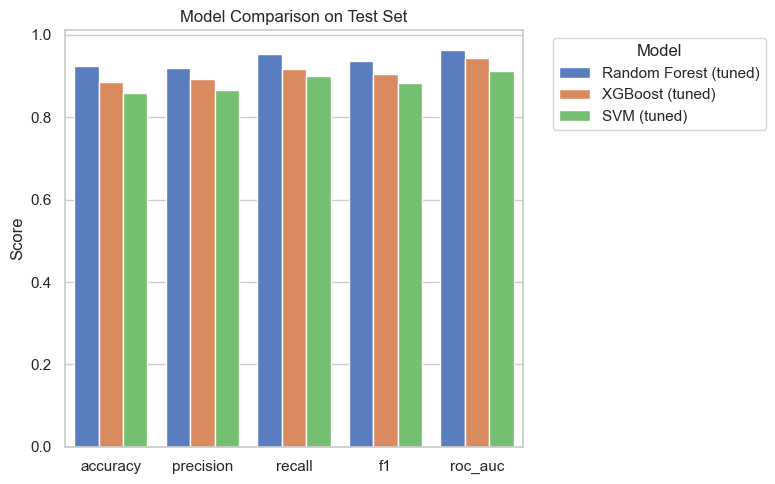

In [54]:
# Model Comparison & Fine-Tuning Summary Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Comparison bar chart (F1, ROC AUC, etc.)
df_compare = pd.DataFrame(evaluation_metrics_test).T[
    ["accuracy", "precision", "recall", "f1", "roc_auc"]
].sort_values("f1", ascending=False)

plt.figure(figsize=(8,5))
sns.barplot(
    data=df_compare.reset_index().melt(id_vars="index", var_name="Metric", value_name="Score"),
    x="Metric", y="Score", hue="index"
)
plt.title("Model Comparison on Test Set")
plt.ylabel("Score")
plt.xlabel("")
plt.legend(title="Model", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [55]:
# Highlight top model
best_model_name = df_compare.index[0]
print(f"Best performing tuned model: {best_model_name}")

Best performing tuned model: Random Forest (tuned)


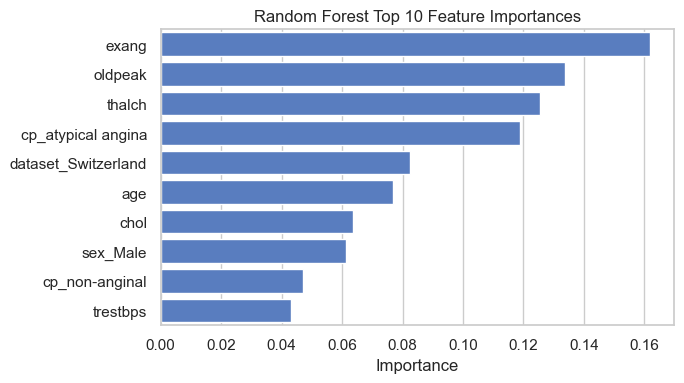

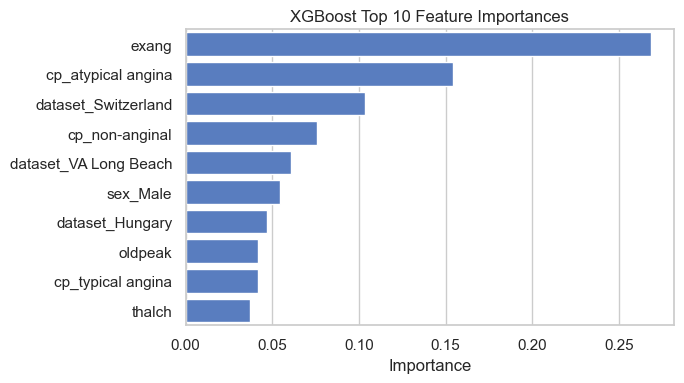

In [56]:
# Feature Importance (only for tree/boosting models)
if "Random Forest (tuned)" in fitted_models:
    rf_best = fitted_models["Random Forest (tuned)"]
    importances = pd.Series(rf_best.feature_importances_, index=X.columns)
    top_rf = importances.sort_values(ascending=False).head(10)
    plt.figure(figsize=(7,4))
    sns.barplot(x=top_rf.values, y=top_rf.index)
    plt.title("Random Forest Top 10 Feature Importances")
    plt.xlabel("Importance")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

if "XGBoost (tuned)" in fitted_models:
    xgb_best = fitted_models["XGBoost (tuned)"]
    try:
        xgb_importances = pd.Series(xgb_best.feature_importances_, index=X.columns)
        top_xgb = xgb_importances.sort_values(ascending=False).head(10)
        plt.figure(figsize=(7,4))
        sns.barplot(x=top_xgb.values, y=top_xgb.index)
        plt.title("XGBoost Top 10 Feature Importances")
        plt.xlabel("Importance")
        plt.ylabel("")
        plt.tight_layout()
        plt.show()
    except Exception as e:
        print(f"Skipping XGBoost importance plot due to: {e}")

In [57]:
# Summary Table
display(df_compare.style.format("{:.3f}"))

,accuracy,precision,recall,f1,roc_auc
Random Forest (tuned),0.924,0.920,0.954,0.937,0.963
XGBoost (tuned),0.886,0.893,0.917,0.905,0.943
SVM (tuned),0.859,0.867,0.899,0.883,0.913


In [58]:
# Consolidated Model Comparison Table
import pandas as pd
import numpy as np

# Cross-validation (original features)
cv_means_df = pd.DataFrame({
    name: {
        "Accuracy": np.mean(raw_cv_results[name]["test_accuracy"]),
        "Precision": np.mean(raw_cv_results[name]["test_precision"]),
        "Recall": np.mean(raw_cv_results[name]["test_recall"]),
        "F1": np.mean(raw_cv_results[name]["test_f1"]),
        "ROC AUC": np.mean(raw_cv_results[name]["test_roc_auc"]),
    }
    for name in raw_cv_results
}).T
cv_means_df.index = [f"{m} (CV)" for m in cv_means_df.index]

# Tuned cross-validation (means only)
tuned_means_df = pd.DataFrame({
    res["name"] + " (tuned)": {
        "Accuracy": np.mean(res["raw_scores"]["test_accuracy"]),
        "Precision": np.mean(res["raw_scores"]["test_precision"]),
        "Recall": np.mean(res["raw_scores"]["test_recall"]),
        "F1": np.mean(res["raw_scores"]["test_f1"]),
        "ROC AUC": np.mean(res["raw_scores"]["test_roc_auc"]),
    }
    for res in tuned_sets
}).T

# Test results
test_means_df = pd.DataFrame(evaluation_metrics_test).T.rename(columns={
    "accuracy": "Accuracy",
    "precision": "Precision",
    "recall": "Recall",
    "f1": "F1",
    "roc_auc": "ROC AUC"
})
test_means_df.index = [f"{m} (Test)" for m in test_means_df.index]

# Combine them
combined_results_df = pd.concat([cv_means_df, tuned_means_df, test_means_df], axis=0)
combined_results_df = combined_results_df.round(3)

# Order rows logically
model_order = []
for base_name in ["Naive Bayes", "SVM", "Random Forest", "XGBoost"]:
    for label in combined_results_df.index:
        if base_name in label:
            model_order.append(label)
combined_results_df = combined_results_df.loc[model_order]

display(
    combined_results_df
        .style
        .format("{:.4f}")
        .set_caption("Consolidated Model Performance Summary (CV, Tuned CV, Test)")
)

,Accuracy,Precision,Recall,F1,ROC AUC
Naive Bayes (CV),0.8160,0.8500,0.8110,0.8300,0.8850
SVM (linear) (CV),0.8150,0.8290,0.8390,0.8340,0.8970
SVM (rbf) (tuned),0.8240,0.8140,0.8840,0.8470,0.8170
SVM (tuned) (Test),0.8590,0.8670,0.8990,0.8830,0.9130
Random Forest (CV),0.8180,0.8280,0.8490,0.8380,0.8800
Random Forest (tuned),0.8250,0.8270,0.8640,0.8450,0.8200
Random Forest (tuned) (Test),0.9240,0.9200,0.9540,0.9370,0.9630
XGBoost (CV),0.7950,0.8030,0.8330,0.8180,0.8610
XGBoost (tuned),0.8320,0.8280,0.8780,0.8520,0.8260
XGBoost (tuned) (Test),0.8860,0.8930,0.9170,0.9050,0.9430


# Ensemble

In [59]:
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
import numpy as np
import pandas as pd

# Build base estimators from the tuned winners you already have
svm_best = fitted_models["SVM (tuned)"]
rf_best  = fitted_models["Random Forest (tuned)"]
xgb_best = fitted_models["XGBoost (tuned)"]

# set weights roughly proportional to CV F1 of tuned models
# (fallback to equal weights if anything missing)
_tuned_f1 = {}
for res in tuned_sets:
    name = res["name"]
    _tuned_f1[name] = float(np.mean(res["raw_scores"]["test_f1"]))
w_svm = _tuned_f1.get("SVM (rbf)", 1.0)
w_rf  = _tuned_f1.get("Random Forest", 1.0)
w_xgb = _tuned_f1.get("XGBoost", 1.0)

# Normalize weights to keep magnitudes reasonable
w_sum = w_svm + w_rf + w_xgb
weights = [w_svm/w_sum, w_rf/w_sum, w_xgb/w_sum]


Voting (soft) performance:
 Accuracy : 0.842
 Precision: 0.877
 Recall   : 0.853
 F1-score : 0.865
 ROC AUC  : 0.910


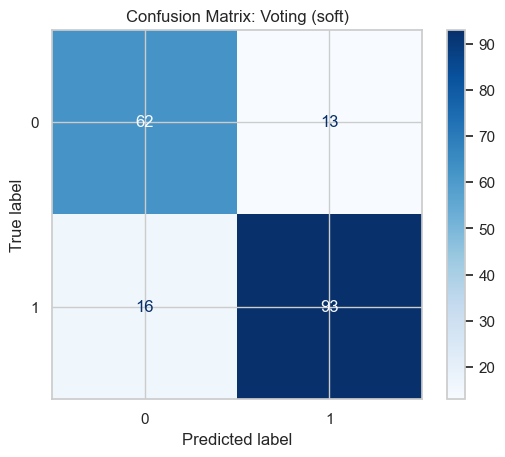


Stacking performance:
 Accuracy : 0.842
 Precision: 0.877
 Recall   : 0.853
 F1-score : 0.865
 ROC AUC  : 0.911


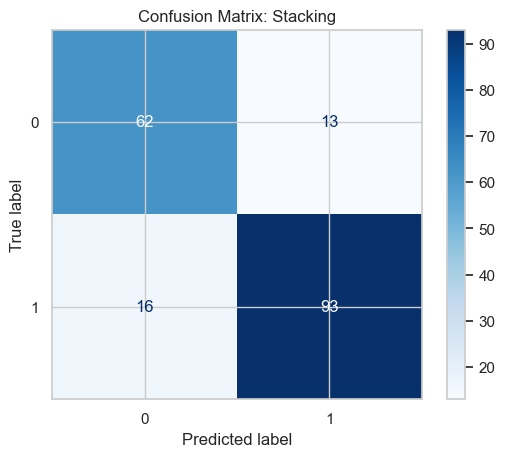

,Accuracy,Precision,Recall,F1,ROC AUC
Naive Bayes (CV),0.8160,0.8500,0.8110,0.8300,0.8850
SVM (linear) (CV),0.8150,0.8290,0.8390,0.8340,0.8970
SVM (rbf) (tuned),0.8240,0.8140,0.8840,0.8470,0.8170
SVM (tuned) (Test),0.8590,0.8670,0.8990,0.8830,0.9130
Random Forest (CV),0.8180,0.8280,0.8490,0.8380,0.8800
Random Forest (tuned),0.8250,0.8270,0.8640,0.8450,0.8200
Random Forest (tuned) (Test),0.9240,0.9200,0.9540,0.9370,0.9630
XGBoost (CV),0.7950,0.8030,0.8330,0.8180,0.8610
XGBoost (tuned),0.8320,0.8280,0.8780,0.8520,0.8260
XGBoost (tuned) (Test),0.8860,0.8930,0.9170,0.9050,0.9430


In [60]:
# Soft Voting (probability averaging)
voting_soft = VotingClassifier(
    estimators=[("svm", svm_best), ("rf", rf_best), ("xgb", xgb_best)],
    voting="soft",
    weights=weights,
    n_jobs=-1
)
voting_soft.fit(X_train, y_train)

# Stacking
stacking = None
try:
    from sklearn.ensemble import StackingClassifier
    stacking = StackingClassifier(
        estimators=[("svm", svm_best), ("rf", rf_best), ("xgb", xgb_best)],
        final_estimator=LogisticRegression(max_iter=1000),
        passthrough=False,          # set True if you also want original features
        n_jobs=-1
    )
    stacking.fit(X_train, y_train)
except Exception as e:
    print(f"Skipping Stacking due to: {e}")

# Cross-validated means for ensembles (to include in consolidated table)
ensemble_cv_means = {}

def _cv_means(model, name):
    scores = cross_validate(
        model, X_train, y_train,
        cv=cv,
        scoring={"accuracy":"accuracy","precision":"precision","recall":"recall",
                 "f1":"f1","roc_auc":"roc_auc"},
        n_jobs=-1
    )
    ensemble_cv_means[name] = {
        "Accuracy": np.mean(scores["test_accuracy"]),
        "Precision": np.mean(scores["test_precision"]),
        "Recall": np.mean(scores["test_recall"]),
        "F1": np.mean(scores["test_f1"]),
        "ROC AUC": np.mean(scores["test_roc_auc"]),
    }

_cv_means(voting_soft, "Voting (soft)")
if stacking is not None:
    _cv_means(stacking, "Stacking")

raw_cv_results["Voting (soft)"] = {k: np.array([v]) for k,v in {
    "test_accuracy": ensemble_cv_means["Voting (soft)"]["Accuracy"],
    "test_precision": ensemble_cv_means["Voting (soft)"]["Precision"],
    "test_recall": ensemble_cv_means["Voting (soft)"]["Recall"],
    "test_f1": ensemble_cv_means["Voting (soft)"]["F1"],
    "test_roc_auc": ensemble_cv_means["Voting (soft)"]["ROC AUC"]
}.items()}
if stacking is not None:
    raw_cv_results["Stacking"] = {k: np.array([v]) for k,v in {
        "test_accuracy": ensemble_cv_means["Stacking"]["Accuracy"],
        "test_precision": ensemble_cv_means["Stacking"]["Precision"],
        "test_recall": ensemble_cv_means["Stacking"]["Recall"],
        "test_f1": ensemble_cv_means["Stacking"]["F1"],
        "test_roc_auc": ensemble_cv_means["Stacking"]["ROC AUC"]
    }.items()}

# Evaluate ensembles on the hold-out test set
fitted_models["Voting (soft)"] = voting_soft
evaluate_on_test("Voting (soft)", voting_soft, X_test, y_test, store=True, target_dict=evaluation_metrics_test)

if stacking is not None:
    fitted_models["Stacking"] = stacking
    evaluate_on_test("Stacking", stacking, X_test, y_test, store=True, target_dict=evaluation_metrics_test)

# Consolidated Model Comparison Table (with Ensembles)
cv_means_df_new = pd.DataFrame({
    name: {
        "Accuracy": np.mean(raw_cv_results[name]["test_accuracy"]),
        "Precision": np.mean(raw_cv_results[name]["test_precision"]),
        "Recall": np.mean(raw_cv_results[name]["test_recall"]),
        "F1": np.mean(raw_cv_results[name]["test_f1"]),
        "ROC AUC": np.mean(raw_cv_results[name]["test_roc_auc"]),
    }
    for name in raw_cv_results
}).T
cv_means_df_new.index = [f"{m} (CV)" for m in cv_means_df_new.index]

# Tuned means (same as before)
tuned_means_df = pd.DataFrame({
    res["name"] + " (tuned)": {
        "Accuracy": np.mean(res["raw_scores"]["test_accuracy"]),
        "Precision": np.mean(res["raw_scores"]["test_precision"]),
        "Recall": np.mean(res["raw_scores"]["test_recall"]),
        "F1": np.mean(res["raw_scores"]["test_f1"]),
        "ROC AUC": np.mean(res["raw_scores"]["test_roc_auc"]),
    }
    for res in tuned_sets
}).T

#  Test set (now includes ensembles)
test_means_df_new = pd.DataFrame(evaluation_metrics_test).T.rename(columns={
    "accuracy":"Accuracy","precision":"Precision","recall":"Recall","f1":"F1","roc_auc":"ROC AUC"
})
test_means_df_new.index = [f"{m} (Test)" for m in test_means_df_new.index]

# Combine & order
combined_results_df = pd.concat([cv_means_df_new, tuned_means_df, test_means_df_new], axis=0)
combined_results_df = combined_results_df.round(3)

# Reasonable ordering: group by base model, then ensembles at the end
model_order = []
for base_name in ["Naive Bayes", "SVM", "Random Forest", "XGBoost"]:
    for label in combined_results_df.index:
        if base_name in label:
            model_order.append(label)
for label in combined_results_df.index:
    if "Voting (soft)" in label or "Stacking" in label:
        model_order.append(label)

combined_results_df = combined_results_df.loc[model_order]
display(combined_results_df.style.format("{:.4f}").set_caption(
    "Consolidated Model Performance Summary (CV, Tuned CV, Test) — with Ensembles"
))